# ANÁLISE EXPLORATÓRIA DE DADOS SOBRE CORRIDA DE TAXIS EM CHICAGO #

Análise com objetivo de encontrar padrões relacionados as empresas de taxis mais usadas, aos principais bairros de destino dos passageiros e avaliar fatores que podem influenciar a duração das viagens.
Contara com uma análise com as informações sobre as o número de corridas por empresa de taxi e quantidade média de viagens finalizadas em cada bairro. Identificando os 10 bairros com maior número de corridas o desempenho das empresas de táxi em relação ao número de corridas e os bairros mais populares como destino das viagens.
Usaremos testes de hipoteses para verificar se as condições climáticas influenciam a duração média das viagens aos sábados.


# LEGENDA DOS DADOS# 

NO DATA SET '/datasets/project_sql_result_01.csv.' 
contém os seguintes dados:

<B>trips_amount:</B> O número de corridas para cada empresa de táxi de 15 a 16 de novembro de 2017.

NO DATA SET '/datasets/project_sql_result_04.csv. ':contém os seguintes dados:

<b>dropoff_location_name:</b> bairros de Chicago onde as corridas terminaram

<b>average_trips:</b> o número médio de viagens que terminaram em cada bairro em novembro de 2017.


# Visão e Analise dos Dados #
Nessa etapa vou importar os arquivos e fazer as limpezas e correções dos dados dos meus dois datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statistics import mode, StatisticsError
from scipy import stats
from math import comb
from scipy.stats import norm, ttest_1samp, ttest_ind, ttest_rel, levene

In [2]:


num_trips = pd.read_csv('/datasets/project_sql_result_01.csv')
print(num_trips.info())
print()
print(num_trips.describe())
print()
num_trips.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None

       trips_amount
count     64.000000
mean    2145.484375
std     3812.310186
min        2.000000
25%       20.750000
50%      178.500000
75%     2106.500000
max    19558.000000



,company_name,trips_amount
0,Flash Cab,19558
1,Taxi Affiliation Services,11422
2,Medallion Leasing,10367
3,Yellow Cab,9888
4,Taxi Affiliation Service Yellow,9299


In [3]:
num_bairros = pd.read_csv('/datasets/project_sql_result_04.csv')
print(num_bairros.info())
print()
print(num_bairros.describe())
print()
num_bairros.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB
None

       average_trips
count      94.000000
mean      599.953728
std      1714.591098
min         1.800000
25%        14.266667
50%        52.016667
75%       298.858333
max     10727.466667



,dropoff_location_name,average_trips
0,Loop,10727.466667
1,River North,9523.666667
2,Streeterville,6664.666667
3,West Loop,5163.666667
4,O'Hare,2546.900000


# VERIFICANDO NUMEROS DUPLICADOS# 

In [4]:
print(num_trips.duplicated())
print(num_bairros.duplicated())

0     False
1     False
2     False
3     False
4     False
      ...  
59    False
60    False
61    False
62    False
63    False
Length: 64, dtype: bool
0     False
1     False
2     False
3     False
4     False
      ...  
89    False
90    False
91    False
92    False
93    False
Length: 94, dtype: bool


# RESULTADOS DA LIMPEZA #
 Os dados estão sem números nulos,e os tipos de dados estão corretos. Avalie transformar os numeros int da coluna trips_amount mas não tem meias corridas então os numeros terão que serem inteiros , enquanto na coluna average_trips é a média de viagens terá que ficar em float pois estamos tirando uma média.

<B> IDENTIFICANDO OS 10 PRINCIPAIS BAIRROS EM TERMOS DE DESTINOS </B>


In [5]:
top_10_bairros = num_bairros.sort_values(
    by='average_trips',
    ascending=False
).head(10)

print(top_10_bairros)

  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


In [6]:

#identificando os numeros das 10 principais empresas de taxi
top_10_taxis = num_trips.sort_values(
    by= 'trips_amount',
    ascending = False
).head(10)
print(top_10_taxis)


                        company_name  trips_amount
0                          Flash Cab         19558
1          Taxi Affiliation Services         11422
2                  Medallion Leasing         10367
3                         Yellow Cab          9888
4    Taxi Affiliation Service Yellow          9299
5          Chicago Carriage Cab Corp          9181
6                       City Service          8448
7                           Sun Taxi          7701
8          Star North Management LLC          7455
9  Blue Ribbon Taxi Association Inc.          5953


# Criação de Gráficos para Análise #

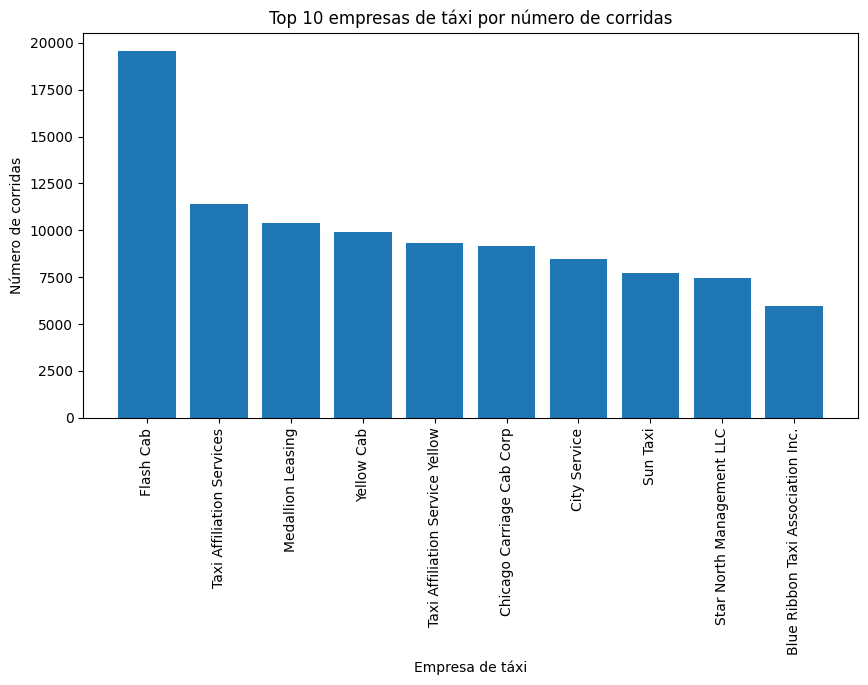

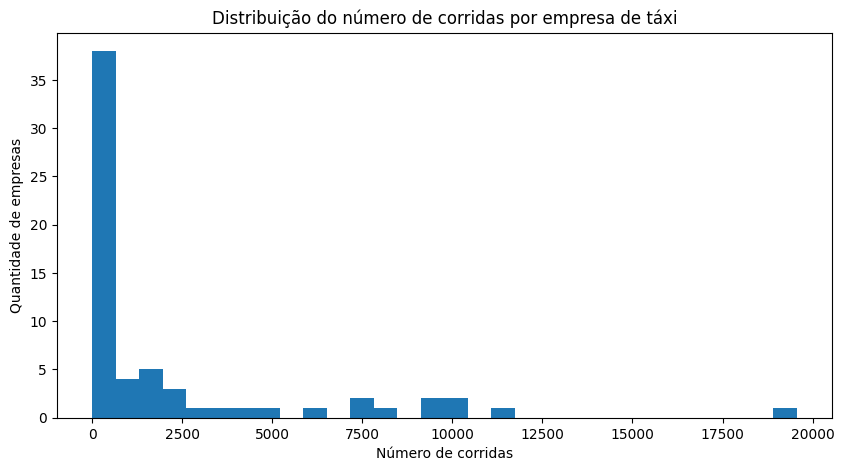

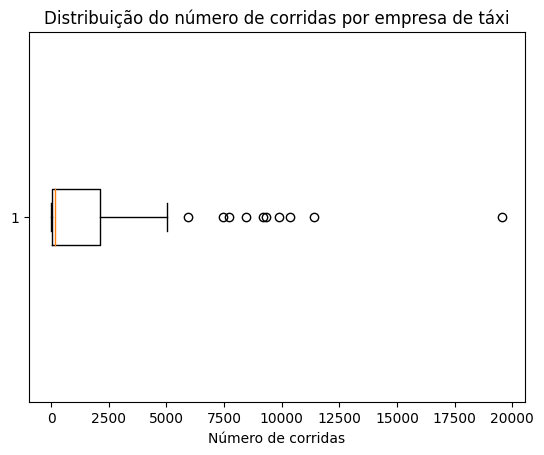

In [7]:
#gráficos de empresas de taxis e números de corridas

plt.figure(figsize=(10,5))

plt.bar(
    top_10_taxis['company_name'],
    top_10_taxis['trips_amount']
)

plt.xticks(rotation=90)

plt.title('Top 10 empresas de táxi por número de corridas')
plt.xlabel('Empresa de táxi')
plt.ylabel('Número de corridas')

plt.show()
#gráfico histograma
plt.figure(figsize=(10,5))

plt.hist(
    num_trips['trips_amount'],
    bins=30
)

plt.title('Distribuição do número de corridas por empresa de táxi')
plt.xlabel('Número de corridas')
plt.ylabel('Quantidade de empresas')

plt.show()

#grafico boxplot


plt.boxplot(
    num_trips['trips_amount'],
    vert=False
)

plt.title('Distribuição do número de corridas por empresa de táxi')
plt.xlabel('Número de corridas')

plt.show()

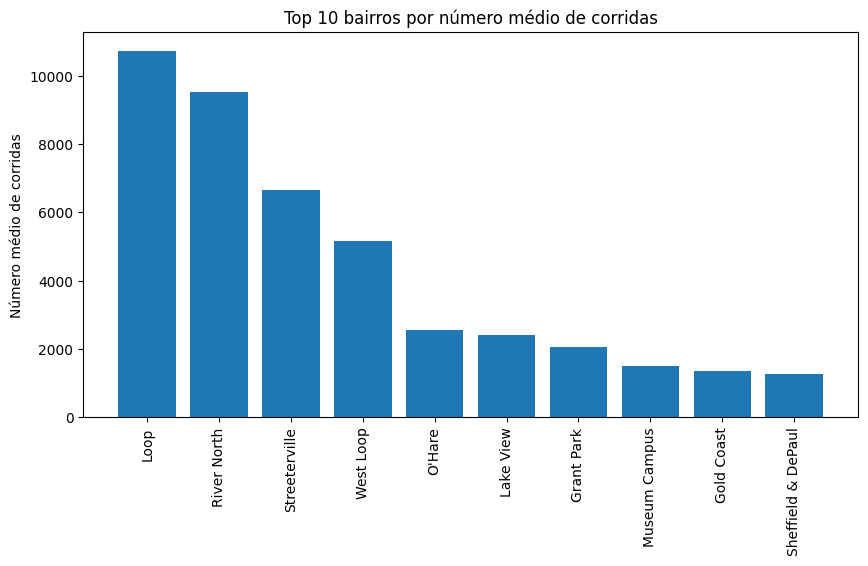

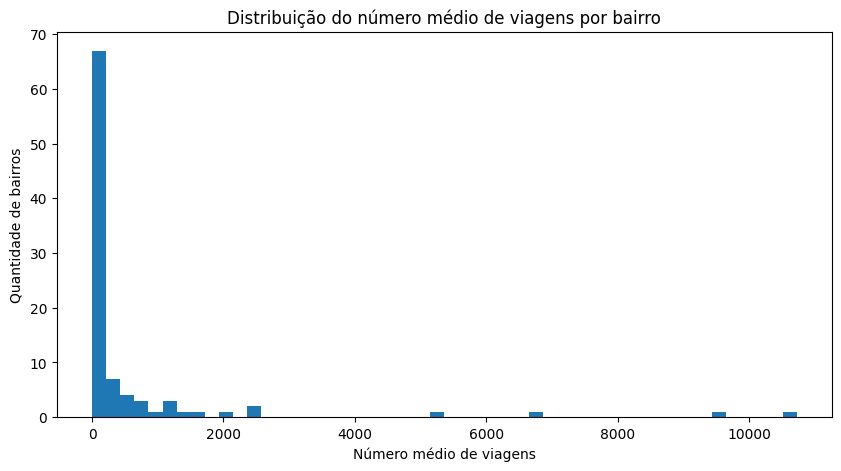

None


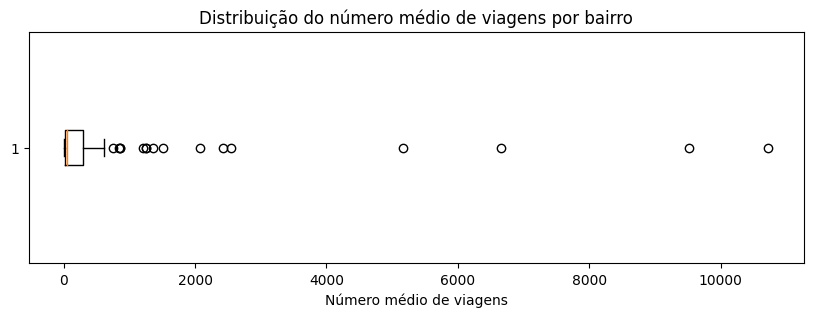

None


In [8]:
# TOP10 BAIRROS POR NÚMERO DE CORRIDAS BASEADOS NO BAIRRO DESTINO
plt.figure(figsize=(10,5))

plt.bar(
    top_10_bairros['dropoff_location_name'],
    top_10_bairros['average_trips']
)

plt.xticks(rotation=90)
plt.title('Top 10 bairros por número médio de corridas')
plt.ylabel('Número médio de corridas')
plt.show()
#gráficos de distribuição e bloxpot empresas de taxis e números de corridas

plt.figure(figsize=(10,5))

plt.hist(
    num_bairros['average_trips'],
    bins=50
)

plt.title('Distribuição do número médio de viagens por bairro')
plt.xlabel('Número médio de viagens')
plt.ylabel('Quantidade de bairros')

print(plt.show())
#bloxpot

plt.figure(figsize=(10,3))

plt.boxplot(
    num_bairros['average_trips'],
    vert=False
)

plt.title('Distribuição do número médio de viagens por bairro')
plt.xlabel('Número médio de viagens')

print(plt.show())



In [9]:
# analisando a diferença de porcentagem da empresa de taxi lider de corridas em chicago
first = top_10_taxis.iloc[0]['trips_amount']
second = top_10_taxis.iloc[1]['trips_amount']

diferenca_percentual = ((first - second) / second) * 100

print(round(diferenca_percentual,2), '%')

71.23 %


In [10]:

# analisando a diferença de porcentagem dos bairros por número de corridas destinadas

primeiro = top_10_bairros.iloc[0]['average_trips']
segundo = top_10_bairros.iloc[1]['average_trips']

diferenca_percentual_1 = ((primeiro - segundo) / segundo) * 100

print(round(diferenca_percentual_1, 2), '%')

12.64 %


# Primeiras conclusões da Análise #
A FlasH Cab é empresa lider nas corridas de Taxi em Chicago, com 71,23% de diferença de corridas da segunda empresa com mais corridas que é a Taxi Affiliation Services. Existe uma grande diferença em corridas dela para as outras empresas, tendo o maior fluxos de carros na rua, com isso gerando mais numeros de corridas.
Já existem 2 bairros com maiores numeros de corridas para eles Loop, River North, mas Loop ainda tem 12.64% a mais de corridas do que River North, são os dois bairros com maiores numeros de corridas os outros bairros se mantém bem abaixo deles.

Existem bairros e corridas com possiveis outliers, mas eu não tenho dados para fazer essa ánalise, pois eles estão com resultados muito diferentes que os outros nos gráficos. Então eu não conseguirei fazer as outras análises por falta de dados.

# TESTE DE HIPÓTESES #

<b>Dicionario de Dados</b>
/datasets/project_sql_result_07.csv — 
 
 Ele contém dados sobre viagens do Loop para o Aeroporto Internacional O'Hare. 
<B>VALORES DAS TABELAS</B> 

<b>start_ts</b>
data e hora de coleta

<b>weather_conditions</b>
condições meteorológicas no momento em que a corrida começou

</b>duration_seconds</b>
duração da corrida em segundos

# Nesta etapa vamos fazer o teste da hipótese: #

"A duração média dos passeios do Loop para o Aeroporto Internacional O'Hare muda nos sábados chuvosos." 

<b>H₀</b>:A duração média dos passeios do Loop para o Aeroporto Internacional O'Hare muda nos sábados chuvosos.

<b/>H₁</b>: A duração média dos passeios do Loop para o Aeroporto Internacional O'Hare  não muda nos sábados chuvosos.

Antes de fazer o teste-t de hipóteses vou limpar e agrupar os dados, escolhi o test-t e o alpha= 0.5 por que os dois são os mais usados por analiticos de dados, e também pois precisamos analisar duas médias, sendo assim melhor usar o test-t



In [11]:
trips_weather = pd.read_csv('/datasets/project_sql_result_07.csv')
print(trips_weather.info())
print()
print(trips_weather.describe())
print()
trips_weather.head()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB
None

       duration_seconds
count       1068.000000
mean        2071.731273
std          769.461125
min            0.000000
25%         1438.250000
50%         1980.000000
75%         2580.000000
max         7440.000000



,start_ts,weather_conditions,duration_seconds
0,2017-11-25 16:00:00,Good,2410.0
1,2017-11-25 14:00:00,Good,1920.0
2,2017-11-25 12:00:00,Good,1543.0
3,2017-11-04 10:00:00,Good,2512.0
4,2017-11-11 07:00:00,Good,1440.0


<b>Vou começar convertendo a coluna de data que esta como obj e vou transformar em datatime, também preciso fazer um filtro para sábado pois vamos observar as corridas no sabado</b>



In [15]:
trips_weather['start_ts'] = pd.to_datetime(trips_weather['start_ts'])

trips_weather['weekday'] =  trips_weather['start_ts'].dt.dayofweek
saturdays = trips_weather[
    trips_weather['weekday'] == 5
]

#separar os sábados de sol e chuva

rayn = saturdays[saturdays['weather_conditions'] == 'Bad']

sun = saturdays[saturdays['weather_conditions'] == 'Good']

#verificar a média de cada dia 

print(rayn['duration_seconds'].mean())
print(sun['duration_seconds'].mean())


2427.2055555555557
1999.6756756756756


In [22]:
# fazendo o test-t 
alpha = 0.05

stat_levene, p_levene = levene(
    rayn['duration_seconds'],
    sun['duration_seconds']
)

if p_levene < alpha:
    equal_var = False
else:
    equal_var = True


t_stat, p_val = ttest_ind(
    rayn['duration_seconds'],
    sun['duration_seconds'],
    equal_var=equal_var
)

rayn = rayn['duration_seconds'].mean()
sun = sun['duration_seconds'].mean()

print(f"Teste t:")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.3f}")
print(f"Média chuva = {rayn:.2f}")
print(f"Média sem chuva = {sun:.2f}")

if p_val < alpha:
    print("Rejeitamos a hipótese nula e concluímos que a duração média dos passeios do Loop para o Aeroporto Internacional O'Hare muda nos sábados chuvosos.")
else:
    print("Não há evidência suficiente para afirmar que a duração média dos passeios do Loop para o Aeroporto Internacional O'Hare muda nos sábados chuvosos.")

Teste t:
t = 6.946, p-valor = 0.000
Média chuva = 2427.21
Média sem chuva = 1999.68
Rejeitamos a hipótese nula e concluímos que a duração média dos passeios do Loop para o Aeroporto Internacional O'Hare muda nos sábados chuvosos.


# Conclusão

Como o previsto com o teste-t a duração média das passeios para o aeroporto aumenta, pode ser influenciavel por muitos fatores dias de chuvas mais carros na rua aumentando o fluxo de carros, menos pessoas indo a pé para não se molhar. Então a nossa hipotese estava certa 